# Evaluating a data stream

A stream is evaluated while it runs, with a confusion matrix that forgets old instances. Three things go
wrong with the usual way of doing it, and each is shown here on a stream simulated in the notebook (no data to
download):

1. a fading F$_1$ falls when the **class prior** changes, even though the classifier did not change, so a
   drop in the number does not tell you whether the model got worse;
2. when the **labels arrive late**, the evaluation either waits for them and lags, or has to use something in
   their place, and the quality of that substitute decides how wrong the estimate is;
3. a **rare class** can leave a short window, and then its per-class value has no number behind it.

`aggmetrics.stream` is experimental (names may change in a later 0.x release) and needs only NumPy.

In [1]:
# Installs the package only where it is missing (for example in Colab).
try:
    from aggmetrics import stream
except ImportError:
    %pip install -q "aggmetrics>=0.4" matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aggmetrics.stream import (ClassTimeState, DelayedEvaluator, TemporalState,
                               attribute, sizing)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## A stream with two different events

A fixed classifier is simulated by its rates, so we know exactly what changes. There are 6,000 steps:

- from step 2,000 the **prior** of the positive class falls from 0.30 to 0.10 (label shift). The classifier
  is the same, with recall 0.80 and specificity 0.90;
- from step 4,000 its **recall** falls from 0.80 to 0.50 (concept drift), at the new prior of 0.10.

In [3]:
rng = np.random.default_rng(7)
T = 6000
t_axis = np.arange(T)
prior = np.where(t_axis < 2000, 0.30, 0.10)
recall = np.where(t_axis < 4000, 0.80, 0.50)
specificity = 0.90

y = (rng.random(T) < prior).astype(int)
y_pred = (rng.random(T) < np.where(y == 1, recall, 1 - specificity)).astype(int)

for name, sl in (("steps 0-1999", slice(0, 2000)), ("steps 2000-3999", slice(2000, 4000)),
                 ("steps 4000-5999", slice(4000, 6000))):
    yy, pp = y[sl], y_pred[sl]
    print(f"{name}: positives {yy.mean():.2f}, recall {pp[yy == 1].mean():.2f}, "
          f"specificity {1 - pp[yy == 0].mean():.2f}")

steps 0-1999: positives 0.30, recall 0.80, specificity 0.91
steps 2000-3999: positives 0.10, recall 0.78, specificity 0.90
steps 4000-5999: positives 0.11, recall 0.52, specificity 0.90


## 1. A fading F$_1$ does not tell the two events apart

A `TemporalState` keeps the confusion matrix with exponential fading (`alpha=0.995`, so the memory is about
200 steps). `compute("f1")` is the usual F$_1$ of that matrix. `compute("f1", prior=0.30)` is the value the same
rates would give at the reference prior of 0.30, so a change of prevalence alone does not move it.

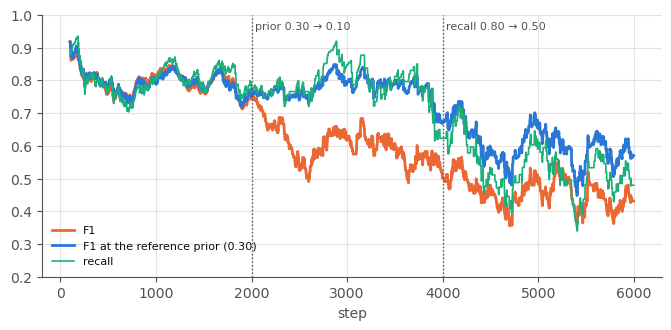

         F1  F1 at prior 0.30
1990  0.758             0.766
2500  0.525             0.740
3990  0.520             0.674
4500  0.472             0.590


In [4]:
state = TemporalState(2, alpha=0.995)
warm = 100                                     # no positive may be missing when a prior is imposed
raw, adjusted, rec = np.full(T, np.nan), np.full(T, np.nan), np.full(T, np.nan)
snap = {}
for t in range(T):
    state.update(y[t], y_pred[t])
    if t >= warm:
        raw[t] = state.compute("f1")
        adjusted[t] = state.compute("f1", prior=0.30)
        rec[t] = state.compute("recall")
    if t in (1999, 3999, 5999):
        snap[t] = state.snapshot()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t_axis, raw, color=ORANGE, label="F1")
ax.plot(t_axis, adjusted, color=BLUE, label="F1 at the reference prior (0.30)")
ax.plot(t_axis, rec, color=AQUA, linewidth=1.2, label="recall")
for x, text in ((2000, "prior 0.30 \u2192 0.10"), (4000, "recall 0.80 \u2192 0.50")):
    ax.axvline(x, color=INK2, linestyle=":", linewidth=1)
    ax.text(x + 40, 0.98, text, fontsize=8, color=INK2, va="top")
ax.set_ylim(0.2, 1.0)
ax.set_xlabel("step")
ax.legend(frameon=False, loc="lower left", fontsize=8)
plt.show()

at = [1990, 2500, 3990, 4500]
print(pd.DataFrame({"F1": raw[at], "F1 at prior 0.30": adjusted[at]}, index=at).round(3))

At step 2,000 the plain F$_1$ falls from 0.76 to 0.53 although nothing happened to the classifier: precision
falls when positives become rarer. The F$_1$ at the reference prior stays near its level (0.77 to 0.74). After
step 4,000, when the rates really change, the plain F$_1$ falls by only 0.05 (0.52 to 0.47) and the adjusted one
by 0.08 (0.67 to 0.59). By the size of the drop, the plain F$_1$ ranks the harmless event as the serious
one. The adjusted series is noisy, because at 10% positives the window holds about 20 of them (the reading of
0.67 at step 3,990 is already a noise-driven dip, before any change).

## 2. Attributing the change

`attribute` splits the change of a measure between two snapshots into the part due to the rates (concept)
and the part due to the prior. We compare the end of each phase.

In [5]:
rows = []
for a, b, label in ((1999, 3999, "label shift (prior 0.30 \u2192 0.10)"),
                    (3999, 5999, "concept drift (recall 0.80 \u2192 0.50)")):
    for method in ("counterfactual", "shapley"):
        at_ = attribute("f1", snap[a], snap[b], method=method)
        rows.append({"event": label, "method": method, "total": at_.total,
                     "concept": at_.concept, "prior": at_.prior, "remainder": at_.remainder,
                     "triage": at_.triage()})
pd.DataFrame(rows).round(3).set_index(["event", "method"])

total  concept  prior  \
event                              method                                  
label shift (prior 0.30 → 0.10)    counterfactual -0.246   -0.082 -0.191   
                                   shapley        -0.246   -0.068 -0.178   
concept drift (recall 0.80 → 0.50) counterfactual -0.069   -0.067 -0.003   
                                   shapley        -0.069   -0.066 -0.003   

                                                   remainder   triage  
event                              method                              
label shift (prior 0.30 → 0.10)    counterfactual      0.027    prior  
                                   shapley             0.000    prior  
concept drift (recall 0.80 → 0.50) counterfactual      0.001  concept  
                                   shapley             0.000  concept

The label shift is attributed mostly to the prior, and the recall drop almost entirely to the concept. The
first row shows a concept part of about $-0.08$ that is not a real change: the rates of the second snapshot
are estimated from about 20 positives, and that estimation noise lands on the concept side. The
attribution classifies a change that something else has already flagged. It does not detect change.

## 3. Rates that do not depend on the prior

A `TemporalState` mixes the prior and the rates. A `ClassTimeState` lets each class forget on its own
arrivals, so its recall and specificity are free of the prior, and a class that stops arriving keeps its last
rates. The price is a memory measured in arrivals of the class, not in steps: with 10% positives, 50
positives take about 500 steps.

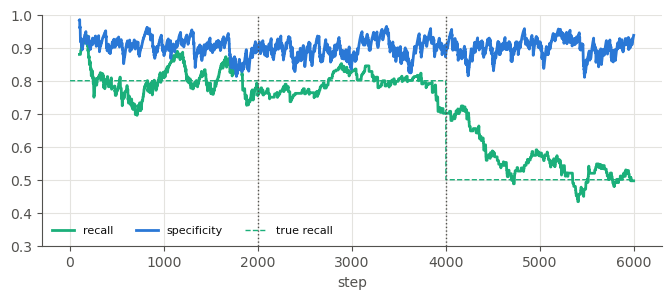

      recall  specificity
1990   0.782        0.901
2500   0.760        0.846
3990   0.701        0.901
4500   0.584        0.849
5990   0.497        0.925


In [6]:
ct = ClassTimeState(2, alpha=0.98)
cr, cs = np.full(T, np.nan), np.full(T, np.nan)
for t in range(T):
    ct.update(y[t], y_pred[t])
    if t >= warm:
        cr[t], cs[t] = ct.canonical_coordinates()

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.plot(t_axis, cr, color=AQUA, label="recall")
ax.plot(t_axis, cs, color=BLUE, label="specificity")
ax.plot(t_axis, recall, color=AQUA, linestyle="--", linewidth=1, label="true recall")
for x in (2000, 4000):
    ax.axvline(x, color=INK2, linestyle=":", linewidth=1)
ax.set_ylim(0.3, 1.0)
ax.set_xlabel("step")
ax.legend(frameon=False, loc="lower left", fontsize=8, ncol=3)
plt.show()

at = [1990, 2500, 3990, 4500, 5990]
print(pd.DataFrame({"recall": cr[at], "specificity": cs[at]}, index=at).round(3))

The recall does not react to the change of prior at step 2,000, and it follows the drop that starts at step 4,000
with a lag (0.58 at step 4,500, 0.50 at step 5,990, against a true value of 0.50). It is noisy, like any rate
estimated from a few dozen positives (0.70 at step 3,990, before the drop), and the specificity moves within
the noise of about 50 effective negatives. Those two numbers are the coordinates a monitor should watch if it
wants to react to concept change and not to prevalence.

## 4. Labels that arrive late

Now every label arrives 100 steps after its instance. Three estimates of the same measure are compared with the
**oracle**, the state that sees each label immediately:

- **labelled only**: a `TemporalState` updated when each label arrives. It is correct about the instances it has
  seen and lags by the delay;
- **interim**: a `DelayedEvaluator`. Each instance enters at once with the model's class probabilities as a stand-in
  for the label, and is corrected when the true label comes.

The stand-in is only as good as the model's calibration, so we try two streams: one where the inputs get
harder but the model stays calibrated, and one where the concept drifts and it does not.

In [7]:
def delayed_run(seed, scenario, delay=100, alpha=0.99, n=5000, change=2500):
    rng = np.random.default_rng(seed)
    easy, hard = rng.beta(1, 3, n), rng.beta(3, 3, n)
    steps = np.arange(n)
    if scenario == "inputs get harder (model stays calibrated)":
        q = np.where(steps < change, easy, hard)       # q is the model's P(y = 1)
        q_true = q
    else:                                              # concept drift: labels become rarer than q says
        q = easy
        q_true = np.where(steps < change, q, q * 0.5)
    y = (rng.random(n) < q_true).astype(int)
    pred = (q > 0.5).astype(int)
    oracle, labelled = TemporalState(2, alpha=alpha), TemporalState(2, alpha=alpha)
    interim = DelayedEvaluator(2, alpha=alpha, eps=1e-3)
    ids, out = {}, []
    for t in range(n):
        oracle.update(y[t], pred[t])
        ids[t] = interim.arrive(np.array([1 - q[t], q[t]]), int(pred[t]))
        if t >= delay:
            labelled.update(y[t - delay], pred[t - delay])
            interim.label(ids[t - delay], int(y[t - delay]))
        if t >= change and t % 20 == 0:
            for m in ("precision", "recall"):
                out.append((t, m, oracle.compute(m), labelled.compute(m), interim.compute(m)))
    return pd.DataFrame(out, columns=["t", "measure", "oracle", "labelled only", "interim"])

scenarios = ["inputs get harder (model stays calibrated)", "concept drift (model not calibrated)"]
runs = {s: [delayed_run(seed, s) for seed in range(5)] for s in scenarios}

rows = []
for s, dfs in runs.items():
    d = pd.concat(dfs)
    d = d[d.t < 3500]                                   # the 1,000 steps after the change
    for m, g in d.groupby("measure"):
        rows.append({"stream": s, "measure": m,
                     "labelled only": (g["labelled only"] - g.oracle).abs().mean(),
                     "interim": (g.interim - g.oracle).abs().mean()})
pd.DataFrame(rows).round(3).set_index(["stream", "measure"])

labelled only  interim
stream                                     measure                          
inputs get harder (model stays calibrated) precision          0.045    0.029
                                           recall             0.069    0.026
concept drift (model not calibrated)       precision          0.091    0.185
                                           recall             0.076    0.055

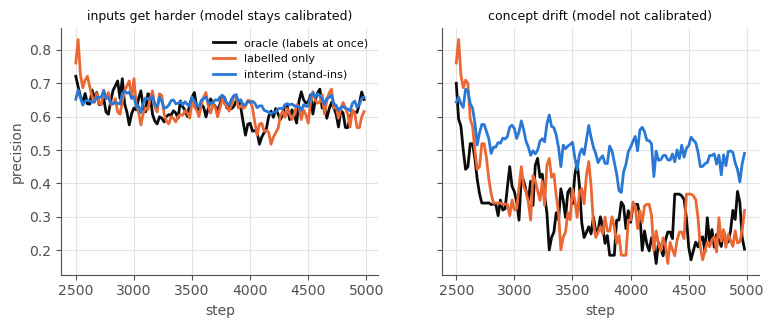

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, s in zip(axes, scenarios):
    d = runs[s][0]
    d = d[d.measure == "precision"]
    ax.plot(d.t, d.oracle, color=INK, label="oracle (labels at once)")
    ax.plot(d.t, d["labelled only"], color=ORANGE, label="labelled only")
    ax.plot(d.t, d.interim, color=BLUE, label="interim (stand-ins)")
    ax.set_title(s, fontsize=9)
    ax.set_xlabel("step")
axes[0].set_ylabel("precision")
axes[0].legend(frameon=False, fontsize=8)
plt.show()

When the model stays calibrated, the interim estimate is closer to the oracle than the labelled-only one for both measures,
because it does not lag. When the concept drifts, the stand-ins are wrong and the interim **precision** is
worse than waiting for the labels, while the interim **recall** is still better. The bias of the interim
estimate follows the calibration error of the stand-in, as the paper shows, and the correction is partial:
it is not a way around not having labels. `ev.coverage()` says which share of each class is verified, so a
value that rests on stand-ins is not mistaken for a measurement.

## 5. A rare class in a short window

Before choosing a window, ask how often a class will be missing from it. `sizing` gives the probability
that a class with prevalence $p$ has no verified instance in a window, with or without label delay, assuming
independent arrivals.

In [9]:
p = 0.02                                               # prevalence of the rare class
print("window 100, no delay        :", round(sizing.undefined_window_probability(p, 100), 3))
print("window 100, delay 25        :", round(sizing.undefined_window_probability(p, 100, delay=25), 3))
print("window for at most 5%, delay 25:", sizing.required_window(p, 0.05, delay=25))
print("queue bound, alpha 0.98     :", sizing.queue_bound(0.98, 1e-3))

window 100, no delay        : 0.133
window 100, delay 25        : 0.22
window for at most 5%, delay 25: 174
queue bound, alpha 0.98     : 149


With a prevalence of 2%, a window of 100 instances has no positive about one time in eight (13%), and about
one in five (22%) when the labels are 25 steps late. A window of 174 keeps that below 5% for the same delay. A macro average over such a window needs a convention for the missing class
(`convention="exclude"`, `"zero"`, `"one"` or `"nan"`, as in notebook 02), and `compute(..., return_audit=True)` reports
which classes had a value.

## What to report

- Say the temporal operator (the fading factor or the window) next to every number.
- If the prior moves, report the measure at a reference prior, or the recall and specificity, next to the plain one.
- Use the attribution to classify a change that a monitor flagged. Do not use it to detect change.
- With late labels, report the verified share (`coverage`), and treat precision, specificity and F$_1$ on stand-ins as
  estimates.
- Size the window for the rarest class before deployment.

Next: the [user guide page on streams](https://aggmetrics.readthedocs.io/en/latest/user_guide/stream.html).